In [21]:
import pandas as pd
import numpy as np
import os

print("Preprocessing notebook is working!")

Preprocessing notebook is working!


In [22]:
import os
import pandas as pd
import numpy as np

raw_folder = "../data/raw/MachineLearningCSV/MachineLearningCVE"
processed_folder = "../data/processed"

os.makedirs(processed_folder, exist_ok=True)

for file in os.listdir(raw_folder):

    if file.endswith(".csv"):

        print("Processing:", file)

        input_path = os.path.join(raw_folder, file)
        output_path = os.path.join(processed_folder, file)

        # Read CSV
        df = pd.read_csv(input_path)

        # 1. Remove extra spaces from column names
        df.columns = df.columns.str.strip()

        # 2. Replace infinite values with NaN
        df.replace([np.inf, -np.inf], np.nan, inplace=True)

        # 3. Remove rows containing missing values
        df.dropna(inplace=True)

        # 4. Remove duplicate rows
        df.drop_duplicates(inplace=True)

        # Save cleaned file
        df.to_csv(output_path, index=False)

        print("Saved:", output_path)
        print("Rows after cleaning:", len(df))
        print()

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Saved: ../data/processed\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows after cleaning: 223082

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Saved: ../data/processed\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows after cleaning: 213777

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Saved: ../data/processed\Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows after cleaning: 184044

Processing: Monday-WorkingHours.pcap_ISCX.csv
Saved: ../data/processed\Monday-WorkingHours.pcap_ISCX.csv
Rows after cleaning: 502650

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Saved: ../data/processed\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows after cleaning: 252790

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Saved: ../data/processed\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows after cleaning: 164179

Processing: Tuesda

In [23]:
import os

processed_folder = "../data/processed"

print("Exists:", os.path.exists(processed_folder))
print("Is folder:", os.path.isdir(processed_folder))
print("Is file:", os.path.isfile(processed_folder))

Exists: True
Is folder: True
Is file: False


In [24]:
import os
import pandas as pd
import numpy as np

processed_folder = "../data/processed"

for file in os.listdir(processed_folder):

    if file.endswith(".csv"):

        path = os.path.join(processed_folder, file)
        data = pd.read_csv(path)

        numeric = data.select_dtypes(include=np.number)

        print("\n", file)
        print("Shape:", data.shape)
        print("Missing:", data.isnull().sum().sum())
        print("Infinite:", np.isinf(numeric).sum().sum())
        print("Duplicates:", data.duplicated().sum())


 Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Shape: (223082, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Shape: (213777, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Friday-WorkingHours-Morning.pcap_ISCX.csv
Shape: (184044, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Monday-WorkingHours.pcap_ISCX.csv
Shape: (502650, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Shape: (252790, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Shape: (164179, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Tuesday-WorkingHours.pcap_ISCX.csv
Shape: (421626, 79)
Missing: 0
Infinite: 0
Duplicates: 0

 Wednesday-workingHours.pcap_ISCX.csv
Shape: (610492, 79)
Missing: 0
Infinite: 0
Duplicates: 0


In [25]:
import os
import pandas as pd

processed_folder = "../data/processed"

all_data = []

for file in os.listdir(processed_folder):

    if file.endswith(".csv"):

        print("Loading:", file)

        path = os.path.join(processed_folder, file)
        data = pd.read_csv(path)

        all_data.append(data)

df = pd.concat(all_data, ignore_index=True)

print("Final dataset shape:", df.shape)

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv
Final dataset shape: (2572640, 79)


In [26]:
df["Label"].value_counts()
df["Label"].value_counts(normalize=True) * 100

Label
BENIGN                        83.451202
DoS Hulk                       6.718624
DDoS                           4.975978
PortScan                       3.525328
DoS GoldenEye                  0.399823
FTP-Patator                    0.230541
DoS slowloris                  0.209318
DoS Slowhttptest               0.203215
SSH-Patator                    0.125124
Bot                            0.075720
Web Attack � Brute Force       0.057140
Web Attack � XSS               0.025344
Infiltration                   0.001399
Web Attack � Sql Injection     0.000816
Heartbleed                     0.000428
Name: proportion, dtype: float64

In [27]:
df.info()
df.dtypes.value_counts()
df.select_dtypes(include="object").columns.tolist()

<class 'pandas.DataFrame'>
RangeIndex: 2572640 entries, 0 to 2572639
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 int64  
 19  Flow IAT Mi

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2924\3949225814.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns.tolist()


['Label']

In [28]:
print(df.columns.tolist())
print(df.describe().T)

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [29]:
# Separate features and target

X = df.drop("Label", axis=1)
y = df["Label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2572640, 78)
Target shape: (2572640,)


In [30]:
print(y.value_counts())

Label
BENIGN                        2146899
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [31]:
# Create binary target

y_binary = y.apply(lambda x: "BENIGN" if x == "BENIGN" else "ATTACK")

print(y_binary.value_counts())
print()
print(y_binary.value_counts(normalize=True) * 100)

Label
BENIGN    2146899
ATTACK     425741
Name: count, dtype: int64

Label
BENIGN    83.451202
ATTACK    16.548798
Name: proportion, dtype: float64


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2058112, 78)
Testing data: (514528, 78)


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (2058112, 78)
Scaled testing data: (514528, 78)


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [35]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, pos_label="ATTACK"))
print("Recall:", recall_score(y_test, y_pred_lr, pos_label="ATTACK"))
print("F1-score:", f1_score(y_test, y_pred_lr, pos_label="ATTACK"))

Accuracy: 0.9579925679457678
Precision: 0.8815122619076213
Recall: 0.8620284680791093
F1-score: 0.8716615008253471


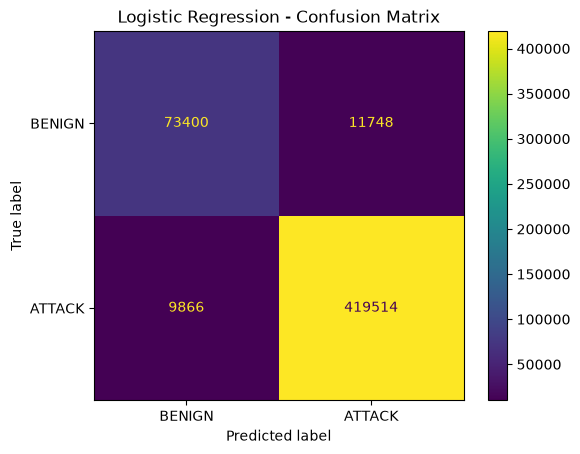

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [37]:
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, pos_label="ATTACK"),
    "Recall": recall_score(y_test, y_pred_lr, pos_label="ATTACK"),
    "F1": f1_score(y_test, y_pred_lr, pos_label="ATTACK")
})

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.957993,0.881512,0.862028,0.871662


In [38]:
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, pos_label="ATTACK"),
    "Recall": recall_score(y_test, y_pred_lr, pos_label="ATTACK"),
    "F1": f1_score(y_test, y_pred_lr, pos_label="ATTACK")
})

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.957993,0.881512,0.862028,0.871662


In [39]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=20
)

model_dt.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [40]:
y_pred_dt = model_dt.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, pos_label="ATTACK")
dt_recall = recall_score(y_test, y_pred_dt, pos_label="ATTACK")
dt_f1 = f1_score(y_test, y_pred_dt, pos_label="ATTACK")

print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1-score:", dt_f1)

Accuracy: 0.9989660426643447
Precision: 0.9958743553680263
Recall: 0.9978860337295062
F1-score: 0.9968791796700847


In [41]:
results.append({
    "Model": "Decision Tree",
    "Accuracy": dt_accuracy,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1": dt_f1
})

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.957993,0.881512,0.862028,0.871662
1,Decision Tree,0.998966,0.995874,0.997886,0.996879


In [42]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [43]:
y_pred_rf = model_rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label="ATTACK")
rf_recall = recall_score(y_test, y_pred_rf, pos_label="ATTACK")
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="ATTACK")

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-score:", rf_f1)

Accuracy: 0.9988222215311897
Precision: 0.9975868725868726
Recall: 0.9952905529196223
F1-score: 0.9964373897707232


In [44]:
results.append({
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1": rf_f1
})

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.957993,0.881512,0.862028,0.871662
1,Decision Tree,0.998966,0.995874,0.997886,0.996879
2,Random Forest,0.998822,0.997587,0.995291,0.996437


In [45]:
import xgboost

print(xgboost.__version__)

3.4.1


In [46]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [47]:
model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

print("XGBoost model created!")

XGBoost model created!


In [49]:

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTarget values:")
print(y_train.value_counts())

X_train shape: (2058112, 78)
y_train shape: (2058112,)

Target values:
Label
BENIGN    1717519
ATTACK     340593
Name: count, dtype: int64


In [52]:

# Encode the target labels
y_train_xgb = y_train.map({
    "BENIGN": 0,
    "ATTACK": 1
})

print("Encoded label counts:")
print(y_train_xgb.value_counts())

print("\nMissing encoded labels:", y_train_xgb.isnull().sum())

# Train XGBoost
model_xgb.fit(X_train, y_train_xgb)

print("\nXGBoost training completed successfully!")

Encoded label counts:
Label
0    1717519
1     340593
Name: count, dtype: int64

Missing encoded labels: 0

XGBoost training completed successfully!


In [53]:
y_pred_xgb = model_xgb.predict(X_test)

print("Prediction completed!")

Prediction completed!


In [55]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Encode the actual test labels
y_test_xgb = y_test.map({
    "BENIGN": 0,
    "ATTACK": 1
})

# Calculate evaluation metrics
print("XGBoost Evaluation Results")
print("--------------------------")

print("Accuracy :", accuracy_score(y_test_xgb, y_pred_xgb))
print("Precision:", precision_score(y_test_xgb, y_pred_xgb))
print("Recall   :", recall_score(y_test_xgb, y_pred_xgb))
print("F1-score :", f1_score(y_test_xgb, y_pred_xgb))

print("\nClassification Report:")
print(
    classification_report(
        y_test_xgb,
        y_pred_xgb,
        target_names=["BENIGN", "ATTACK"]
    )
)

XGBoost Evaluation Results
--------------------------
Accuracy : 0.999179830835251
Precision: 0.9970899532984441
Recall   : 0.997956499271856
F1-score : 0.997523038093561

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    429380
      ATTACK       1.00      1.00      1.00     85148

    accuracy                           1.00    514528
   macro avg       1.00      1.00      1.00    514528
weighted avg       1.00      1.00      1.00    514528



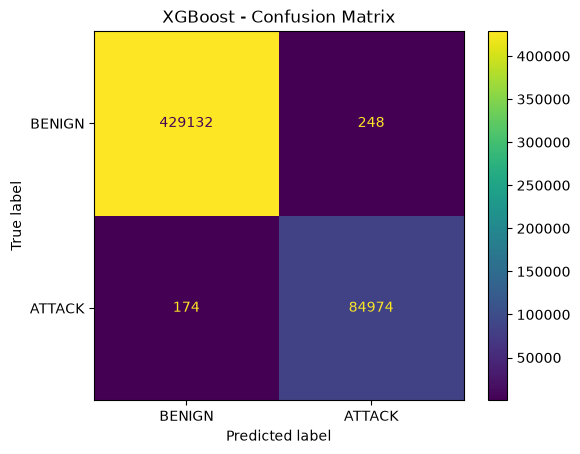

Confusion Matrix:
[[429132    248]
 [   174  84974]]


In [57]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test_xgb, y_pred_xgb)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot()
plt.title("XGBoost - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

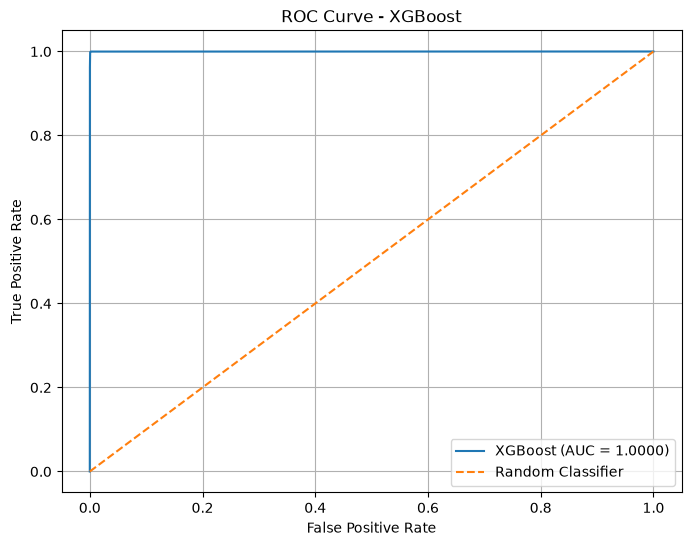

XGBoost ROC-AUC: 0.9999722115309434


In [67]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get attack probabilities
y_prob_xgb = model_xgb.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test_xgb, y_prob_xgb)

# Calculate AUC
roc_auc = roc_auc_score(y_test_xgb, y_prob_xgb)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

print("XGBoost ROC-AUC:", roc_auc)

In [76]:

# Check whether train and test indices overlap

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nSame index values in train and test:",
      len(X_train.index.intersection(X_test.index)))

# Check for non-finite values in the feature matrices
import numpy as np

print("\nNon-finite values in X_train:",
      np.size(X_train.to_numpy()) -
      np.isfinite(X_train.to_numpy()).sum())

print("Non-finite values in X_test:",
      np.size(X_test.to_numpy()) -
      np.isfinite(X_test.to_numpy()).sum())

Training rows: 2058112
Testing rows: 514528

Same index values in train and test: 0

Non-finite values in X_train: 0
Non-finite values in X_test: 0


In [89]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Convert both actual and predicted labels consistently
def convert_labels(labels):
    labels = pd.Series(labels).reset_index(drop=True)

    return labels.replace({
        "BENIGN": 0,
        "ATTACK": 1
    }).astype(int)

# Actual test labels
y_true = convert_labels(y_test)

# Predictions from all four models
y_pred_lr = convert_labels(model_lr.predict(X_test))
y_pred_dt = convert_labels(model_dt.predict(X_test))
y_pred_rf = convert_labels(model_rf.predict(X_test))
y_pred_xgb_numeric = convert_labels(y_pred_xgb)

# Compare models
model_predictions = [
    ("Logistic Regression", y_pred_lr),
    ("Decision Tree", y_pred_dt),
    ("Random Forest", y_pred_rf),
    ("XGBoost", y_pred_xgb_numeric)
]

results = []

for name, predictions in model_predictions:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(5).to_string(index=False))

c:\Network-Intrusion-Detection\venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression   0.79752    0.34046 0.23849   0.28050
      Decision Tree   0.99897    0.99587 0.99789   0.99688
      Random Forest   0.99882    0.99759 0.99529   0.99644
            XGBoost   0.99918    0.99709 0.99796   0.99752


In [96]:

# Check duplicate rows in the cleaned feature dataset

print("Total training rows:", len(X_train))
print("Duplicate training feature rows:", X_train.duplicated().sum())

print("\nTotal testing rows:", len(X_test))
print("Duplicate testing feature rows:", X_test.duplicated().sum())

# Check how many test feature rows also appear in training
train_hashes = set(
    pd.util.hash_pandas_object(X_train, index=False)
)

test_hashes = pd.util.hash_pandas_object(X_test, index=False)

print(
    "\nTest rows with matching training feature hashes:",
    test_hashes.isin(train_hashes).sum()
)

Total training rows: 2058112
Duplicate training feature rows: 36347

Total testing rows: 514528
Duplicate testing feature rows: 2908

Test rows with matching training feature hashes: 15144


In [102]:

import pandas as pd

# Combine training and testing features with their true labels
train_check = X_train.copy()
train_check["Label"] = y_train.reset_index(drop=True).values

test_check = X_test.copy()
test_check["Label"] = y_test.reset_index(drop=True).values

# Find feature rows appearing in both datasets
combined_check = pd.concat(
    [train_check, test_check],
    ignore_index=True
)

# Count distinct labels for each unique feature combination
label_counts = combined_check.groupby(
    list(X_train.columns),
    dropna=False
)["Label"].nunique()

# Feature combinations associated with multiple labels
conflicting_features = label_counts[label_counts > 1]

print(
    "Unique feature combinations with conflicting labels:",
    len(conflicting_features)
)

print(
    "Total unique feature combinations:",
    len(label_counts)
)

Unique feature combinations with conflicting labels: 697
Total unique feature combinations: 2520101


In [107]:

# Inspect conflicting feature combinations and their labels

conflict_details = (
    combined_check.groupby(
        list(X_train.columns),
        dropna=False
    )["Label"]
    .agg(
        record_count="size",
        number_of_labels="nunique",
        labels=lambda labels: list(labels.unique())
    )
    .reset_index()
)

conflict_details = conflict_details[
    conflict_details["number_of_labels"] > 1
]

print("Conflicting feature combinations:", len(conflict_details))

print("\nFirst 10 conflicting combinations:")
print(
    conflict_details[
        ["record_count", "number_of_labels", "labels"]
    ].head(10).to_string(index=False)
)

print(
    "\nTotal records belonging to conflicting combinations:",
    conflict_details["record_count"].sum()
)

Conflicting feature combinations: 697

First 10 conflicting combinations:
 record_count  number_of_labels           labels
            2                 2 [BENIGN, ATTACK]
            2                 2 [ATTACK, BENIGN]
            2                 2 [ATTACK, BENIGN]
            2                 2 [BENIGN, ATTACK]
            2                 2 [BENIGN, ATTACK]
            2                 2 [ATTACK, BENIGN]
            2                 2 [BENIGN, ATTACK]
            2                 2 [ATTACK, BENIGN]
            2                 2 [ATTACK, BENIGN]
            2                 2 [BENIGN, ATTACK]

Total records belonging to conflicting combinations: 1412


In [111]:
import pandas as pd

train_check = pd.DataFrame({
    "row_hash": pd.util.hash_pandas_object(X_train, index=False).values,
    "Label": y_train.to_numpy(),
    "Split": "Train"
})

test_check = pd.DataFrame({
    "row_hash": pd.util.hash_pandas_object(X_test, index=False).values,
    "Label": y_test.to_numpy(),
    "Split": "Test"
})

all_check = pd.concat(
    [train_check, test_check],
    ignore_index=True
)

# Find identical feature rows with conflicting labels
label_counts = all_check.groupby("row_hash")["Label"].nunique()
conflict_hashes = label_counts[label_counts > 1].index

conflict_rows = all_check[
    all_check["row_hash"].isin(conflict_hashes)
]

print("Conflicting feature combinations:", len(conflict_hashes))
print("\nConflicting records by split and label:")
print(pd.crosstab(conflict_rows["Split"], conflict_rows["Label"]))

print(
    "\nConflicting combinations appearing in both train and test:",
    conflict_rows.groupby("row_hash")["Split"].nunique().eq(2).sum()
)

Conflicting feature combinations: 697

Conflicting records by split and label:
Label  ATTACK  BENIGN
Split                
Test      149     123
Train     548     592

Conflicting combinations appearing in both train and test: 229


In [112]:
train_rows = pd.DataFrame({
    "row_hash": pd.util.hash_pandas_object(
        X_train, index=False
    ).values,
    "Label": y_train.to_numpy()
})

test_rows = pd.DataFrame({
    "row_hash": pd.util.hash_pandas_object(
        X_test, index=False
    ).values,
    "Label": y_test.to_numpy()
})

# Get the set of labels associated with each training feature combination
train_labels = train_rows.groupby("row_hash")["Label"].agg(
    lambda x: set(x)
)

test_rows["train_labels"] = test_rows["row_hash"].map(train_labels)

# Test rows whose feature combinations exist in training
overlap = test_rows[test_rows["train_labels"].notna()].copy()

overlap["label_matches_training"] = overlap.apply(
    lambda row: row["Label"] in row["train_labels"],
    axis=1
)

print("Test rows with matching training features:", len(overlap))

print(
    "Rows with a label also seen for those training features:",
    overlap["label_matches_training"].sum()
)

print(
    "Rows whose label differs from all training labels for those features:",
    (~overlap["label_matches_training"]).sum()
)

Test rows with matching training features: 15144
Rows with a label also seen for those training features: 14920
Rows whose label differs from all training labels for those features: 224


In [113]:
# Identify test rows whose feature combination exists in training,
# but whose label is absent for that combination in training.

conflicting_test = overlap[
    ~overlap["label_matches_training"]
].copy()

print("Conflicting test rows:", len(conflicting_test))

print("\nTheir actual test labels:")
print(conflicting_test["Label"].value_counts())

print("\nLabels recorded for their matching training features:")
print(conflicting_test["train_labels"].value_counts().head(10))

Conflicting test rows: 224

Their actual test labels:
Label
ATTACK    128
BENIGN     96
Name: count, dtype: int64

Labels recorded for their matching training features:
train_labels
{BENIGN}    128
{ATTACK}     96
Name: count, dtype: int64


In [115]:
# Remove rows with no matching training features first
matched = test_hashes[test_hashes["train_labels"].apply(
    lambda x: isinstance(x, set)
)].copy()

# Identify rows whose test label is absent from training labels
conflicting_test = matched[
    matched.apply(
        lambda r: r["Label"] not in r["train_labels"],
        axis=1
    )
]

print("Conflicting test rows:", len(conflicting_test))
print("\nLabels:")
print(conflicting_test["Label"].value_counts())

Conflicting test rows: 224

Labels:
Label
ATTACK    128
BENIGN     96
Name: count, dtype: int64


In [116]:

# Display the first 10 conflicting rows
print("Conflicting rows:")
display(conflicting_test[["hash", "Label", "train_labels"]].head(10))

# Count conflicting labels
print("\nConflicting label counts:")
print(conflicting_test["Label"].value_counts())

# Check whether the same feature hash has multiple labels in training
print("\nNumber of unique conflicting hashes:")
print(conflicting_test["hash"].nunique())

print("\nSample training label sets:")
display(conflicting_test[["hash", "train_labels"]].head(10))

Conflicting rows:


,hash,Label,train_labels
353,3808042456287408840,ATTACK,{BENIGN}
1680,13757035771582153390,BENIGN,{ATTACK}
4545,5116372817156667420,BENIGN,{ATTACK}
4886,8538751377538118664,ATTACK,{BENIGN}
7393,11133981708603731302,BENIGN,{ATTACK}
16686,6050227154632928041,ATTACK,{BENIGN}
19218,16179890482509366933,ATTACK,{BENIGN}
20338,5061910741216530683,ATTACK,{BENIGN}
20721,6998155207987402381,BENIGN,{ATTACK}
22568,3063496016917007405,ATTACK,{BENIGN}



Conflicting label counts:
Label
ATTACK    128
BENIGN     96
Name: count, dtype: int64

Number of unique conflicting hashes:
224

Sample training label sets:


,hash,train_labels
353,3808042456287408840,{BENIGN}
1680,13757035771582153390,{ATTACK}
4545,5116372817156667420,{ATTACK}
4886,8538751377538118664,{BENIGN}
7393,11133981708603731302,{ATTACK}
16686,6050227154632928041,{BENIGN}
19218,16179890482509366933,{BENIGN}
20338,5061910741216530683,{BENIGN}
20721,6998155207987402381,{ATTACK}
22568,3063496016917007405,{BENIGN}


In [117]:

# Check which original datasets are available
for name in ["X_train", "X_test", "y_train", "y_test",
             "X_train_scaled", "X_test_scaled"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: shape={getattr(obj, 'shape', 'unknown')}")
    else:
        print(f"{name}: not found")

print("\nTrain hash table:")
display(train_hashes.head())

print("\nTest hash table:")
display(test_hashes.head())

print("\nHash table columns:")
print("train_hashes:", train_hashes.columns.tolist())
print("test_hashes:", test_hashes.columns.tolist())

X_train: shape=(2058112, 78)
X_test: shape=(514528, 78)
y_train: shape=(2058112,)
y_test: shape=(514528,)
X_train_scaled: shape=(2058112, 78)
X_test_scaled: shape=(514528, 78)

Train hash table:


,hash,Label
0,8325582518408895021,BENIGN
1,3623989878661104849,BENIGN
2,16755990057296559748,BENIGN
3,17122780389973704540,BENIGN
4,10061486166548688485,BENIGN



Test hash table:


,hash,Label,train_labels
0,4278999154088243912,ATTACK,NaN
1,12462425640837570469,BENIGN,NaN
2,6346949376608815301,BENIGN,NaN
3,11366161459826320012,BENIGN,NaN
4,16581887067414480992,ATTACK,NaN



Hash table columns:
train_hashes: ['hash', 'Label']
test_hashes: ['hash', 'Label', 'train_labels']


In [118]:

import numpy as np
import pandas as pd

# Find the first conflicting hash
sample_hash = conflicting_test.iloc[0]["hash"]

print("Sample hash:", sample_hash)

# Find the test row's position in the original test data
test_pos = conflicting_test.index[0]

print("Test row index:", test_pos)
print("Test label:", y_test.iloc[test_pos]
      if hasattr(y_test, "iloc") else y_test[test_pos])

# Find matching training rows using the hash table
train_positions = np.flatnonzero(
    train_hashes["hash"].to_numpy() == sample_hash
)

print("Matching training rows:", len(train_positions))

if len(train_positions) > 0:
    train_pos = train_positions[0]

    # Compare the original feature values
    test_features = np.asarray(X_test)[test_pos]
    train_features = np.asarray(X_train)[train_pos]

    print("Training label:",
          train_hashes.iloc[train_pos]["Label"])

    print("Exact feature match:",
          np.array_equal(test_features, train_features))

    print("Number of differing features:",
          np.count_nonzero(test_features != train_features))

    print("\nFirst 10 test feature values:")
    print(test_features[:10])

    print("\nFirst 10 train feature values:")
    print(train_features[:10])
else:
    print("No matching training position found for this hash.")

Sample hash: 3808042456287408840
Test row index: 353
Test label: ATTACK
Matching training rows: 1
Training label: BENIGN
Exact feature match: True
Number of differing features: 0

First 10 test feature values:
[593.  48.   1.   1.   2.   6.   2.   2.   2.   0.]

First 10 train feature values:
[593.  48.   1.   1.   2.   6.   2.   2.   2.   0.]


In [119]:

import numpy as np

X_train_array = np.asarray(X_train)
X_test_array = np.asarray(X_test)

train_hash_array = train_hashes["hash"].to_numpy()

exact_matches = 0
mismatches = 0
missing_matches = 0

for test_pos in conflicting_test.index:
    sample_hash = test_hashes.loc[test_pos, "hash"]

    train_positions = np.flatnonzero(
        train_hash_array == sample_hash
    )

    if len(train_positions) == 0:
        missing_matches += 1
        continue

    test_row = X_test_array[test_pos]

    # Verify against every training row with this hash
    found_exact = any(
        np.array_equal(test_row, X_train_array[train_pos])
        for train_pos in train_positions
    )

    if found_exact:
        exact_matches += 1
    else:
        mismatches += 1

print("Conflicting test rows:", len(conflicting_test))
print("Exact feature matches:", exact_matches)
print("Feature mismatches:", mismatches)
print("Missing training matches:", missing_matches)

Conflicting test rows: 224
Exact feature matches: 224
Feature mismatches: 0
Missing training matches: 0


In [120]:

print("Available label-related variables:")

for name in ["y_attack", "y_binary", "y", "df", "data"]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj), getattr(obj, "shape", ""))

Available label-related variables:
y_attack <class 'pandas.Series'> (425741,)
y_binary <class 'pandas.Series'> (2572640,)
y <class 'pandas.Series'> (2572640,)
df <class 'pandas.DataFrame'> (2572640, 79)
data <class 'pandas.DataFrame'> (610492, 79)


In [121]:

# Inspect the available processed dataset
if "df" in globals() and hasattr(df, "columns"):
    print(df.columns.tolist())
    print(df["Label"].value_counts().head(20))

elif "data" in globals() and hasattr(data, "columns"):
    print(data.columns.tolist())
    print(data["Label"].value_counts().head(20))

elif "y_attack" in globals():
    print(y_attack.value_counts().head(20))

else:
    print("Processed dataset variable not identified yet.")

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [122]:

import numpy as np
import pandas as pd

# The 78 feature columns used for training
feature_cols = list(X_train.columns)

# Check whether the feature columns match the processed dataset
print("Feature count:", len(feature_cols))
print("All features in df:", all(c in df.columns for c in feature_cols))

# Inspect the original labels for the first few conflicting rows
for test_pos in list(conflicting_test.index[:10]):
    test_features = X_test.iloc[test_pos]

    # Find identical feature rows in the original dataset
    mask = df[feature_cols].eq(test_features, axis="columns").all(axis=1)
    original_rows = df.loc[mask, ["Label"]]

    print("\nTest index:", test_pos)
    print("Test binary label:", test_hashes.loc[test_pos, "Label"])
    print("Original dataset labels:")
    print(original_rows["Label"].value_counts().to_dict())

Feature count: 78
All features in df: True

Test index: 353
Test binary label: ATTACK
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 1680
Test binary label: BENIGN
Original dataset labels:
{'DoS Hulk': 1, 'BENIGN': 1}

Test index: 4545
Test binary label: BENIGN
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 4886
Test binary label: ATTACK
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 7393
Test binary label: BENIGN
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 16686
Test binary label: ATTACK
Original dataset labels:
{'BENIGN': 1, 'DoS Hulk': 1}

Test index: 19218
Test binary label: ATTACK
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 20338
Test binary label: ATTACK
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 20721
Test binary label: BENIGN
Original dataset labels:
{'PortScan': 1, 'BENIGN': 1}

Test index: 22568
Test binary label: ATTACK
Original dataset labels:
{'

In [123]:

import pandas as pd

# Verify that the same hashing method reproduces a known hash
sample_pos = conflicting_test.index[0]

sample_hash_check = pd.util.hash_pandas_object(
    X_test.iloc[[sample_pos]],
    index=False
).iloc[0]

print("Existing hash:", test_hashes.loc[sample_pos, "hash"])
print("Recomputed hash:", sample_hash_check)
print("Hash matches:", sample_hash_check == test_hashes.loc[sample_pos, "hash"])

Existing hash: 3808042456287408840
Recomputed hash: 3808042456287408840
Hash matches: True


In [124]:

# Create a hash for every original feature row
df_hashes = pd.util.hash_pandas_object(
    df[feature_cols],
    index=False
)

# Count distinct original labels associated with each feature hash
label_counts = pd.DataFrame({
    "hash": df_hashes.to_numpy(),
    "Label": df["Label"].to_numpy()
}).groupby("hash")["Label"].nunique()

conflict_hashes = label_counts[label_counts > 1]

print("Total dataset rows:", len(df))
print("Unique feature hashes:", df_hashes.nunique())
print("Feature hashes with multiple labels:", len(conflict_hashes))
print(
    "Rows belonging to conflicting feature groups:",
    df_hashes.isin(conflict_hashes.index).sum()
)

print("\nMost common conflicting label groups:")
conflict_details = pd.DataFrame({
    "hash": df_hashes.to_numpy(),
    "Label": df["Label"].to_numpy()
})

print(
    conflict_details[
        conflict_details["hash"].isin(conflict_hashes.index)
    ].groupby(["hash", "Label"]).size().head(20)
)

Total dataset rows: 2572640
Unique feature hashes: 2520101
Feature hashes with multiple labels: 697
Rows belonging to conflicting feature groups: 1412

Most common conflicting label groups:
hash                Label   
8370787859145599    BENIGN      1
                    PortScan    1
38227122635730256   BENIGN      1
                    PortScan    1
58175373278617653   BENIGN      1
                    PortScan    1
78648907410353886   BENIGN      1
                    PortScan    1
97607990746794942   BENIGN      1
                    PortScan    1
129440869859764056  BENIGN      1
                    PortScan    1
161063990953879959  BENIGN      1
                    DoS Hulk    1
191575008513063953  BENIGN      1
                    PortScan    1
246980840227270741  BENIGN      1
                    PortScan    1
311459902668532356  BENIGN      1
                    PortScan    1
dtype: int64


In [125]:

# Show all original labels associated with each conflicting hash
conflict_groups = (
    conflict_details[
        conflict_details["hash"].isin(conflict_hashes.index)
    ]
    .groupby("hash")["Label"]
    .agg(lambda labels: sorted(set(labels)))
)

print("Number of conflicting feature groups:", len(conflict_groups))

print("\nLabel combinations and their frequencies:")
print(
    conflict_groups.value_counts()
    .head(20)
    .to_string()
)

print("\nSample conflicting groups:")
display(conflict_groups.head(15).to_frame("Labels"))

Number of conflicting feature groups: 697

Label combinations and their frequencies:
Label
[BENIGN, PortScan]         564
[BENIGN, DoS Hulk]         129
[BENIGN, DDoS]               3
[BENIGN, DoS slowloris]      1

Sample conflicting groups:


,Labels
hash,
8370787859145599,"[BENIGN, PortScan]"
38227122635730256,"[BENIGN, PortScan]"
58175373278617653,"[BENIGN, PortScan]"
78648907410353886,"[BENIGN, PortScan]"
97607990746794942,"[BENIGN, PortScan]"
129440869859764056,"[BENIGN, PortScan]"
161063990953879959,"[BENIGN, DoS Hulk]"
191575008513063953,"[BENIGN, PortScan]"
246980840227270741,"[BENIGN, PortScan]"


In [126]:

from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import pandas as pd

# Use the original 78 features
X_all = df[feature_cols].copy()

# Binary target: BENIGN = 0, any attack = 1
y_all = (
    df["Label"].astype(str).str.strip()
    .ne("BENIGN").astype("int8")
)

# Group identical feature vectors together
groups = df_hashes.to_numpy()

# Split groups, not individual rows
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_all, y_all, groups=groups)
)

X_train_group = X_all.iloc[train_idx].copy()
X_test_group = X_all.iloc[test_idx].copy()

y_train_group = y_all.iloc[train_idx].copy()
y_test_group = y_all.iloc[test_idx].copy()

# Verify that no feature group crosses the split
train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

print("Training shape:", X_train_group.shape)
print("Testing shape:", X_test_group.shape)
print("Training labels:")
print(y_train_group.value_counts())
print("\nTesting labels:")
print(y_test_group.value_counts())

print("\nOverlapping feature groups:", len(train_groups & test_groups))
print("Training attack percentage:",
      round(y_train_group.mean() * 100, 3), "%")
print("Testing attack percentage:",
      round(y_test_group.mean() * 100, 3), "%")

Training shape: (2057935, 78)
Testing shape: (514705, 78)
Training labels:
Label
0    1717648
1     340287
Name: count, dtype: int64

Testing labels:
Label
0    429251
1     85454
Name: count, dtype: int64

Overlapping feature groups: 0
Training attack percentage: 16.535 %
Testing attack percentage: 16.603 %


In [127]:

from sklearn.preprocessing import StandardScaler

scaler_group = StandardScaler()

X_train_group_scaled = scaler_group.fit_transform(X_train_group)
X_test_group_scaled = scaler_group.transform(X_test_group)

print("Scaled training shape:", X_train_group_scaled.shape)
print("Scaled testing shape:", X_test_group_scaled.shape)
print("Scaler fitted on training data only.")

Scaled training shape: (2057935, 78)
Scaled testing shape: (514705, 78)
Scaler fitted on training data only.


In [128]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

models_group = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}

results_group = []
trained_models_group = {}

for name, model in models_group.items():
    print("Training:", name)

    # Logistic Regression uses scaled features
    if name == "Logistic Regression":
        model.fit(X_train_group_scaled, y_train_group)
        predictions = model.predict(X_test_group_scaled)
    else:
        model.fit(X_train_group, y_train_group)
        predictions = model.predict(X_test_group)

    trained_models_group[name] = model

    results_group.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_group, predictions),
        "Precision": precision_score(
            y_test_group, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_group, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_group, predictions, zero_division=0
        )
    })

results_group_df = pd.DataFrame(results_group)
results_group_df = results_group_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

print("\nRevised group-aware model comparison:")
display(results_group_df.round(5))

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: XGBoost

Revised group-aware model comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,XGBoost,0.99893,0.99620,0.99737,0.99678
1,Random Forest,0.99876,0.99633,0.99622,0.99627
2,Decision Tree,0.99862,0.99586,0.99586,0.99586
3,Logistic Regression,0.95680,0.87718,0.86023,0.86862


Confusion Matrix:
[[428926    325]
 [   225  85229]]

Classification Report:
              precision    recall  f1-score   support

      BENIGN    0.99948   0.99924   0.99936    429251
      ATTACK    0.99620   0.99737   0.99678     85454

    accuracy                        0.99893    514705
   macro avg    0.99784   0.99830   0.99807    514705
weighted avg    0.99893   0.99893   0.99893    514705



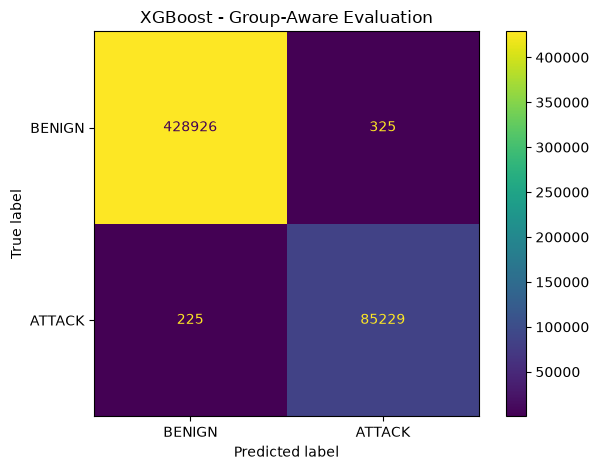

In [129]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions from the trained XGBoost model
best_model_group = trained_models_group["XGBoost"]

y_pred_xgb_group = best_model_group.predict(X_test_group)

# Confusion matrix
cm = confusion_matrix(
    y_test_group,
    y_pred_xgb_group,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test_group,
    y_pred_xgb_group,
    target_names=["BENIGN", "ATTACK"],
    digits=5
))

# Plot the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

display.plot(values_format="d")
plt.title("XGBoost - Group-Aware Evaluation")
plt.tight_layout()
plt.show()

ROC-AUC: 0.999952


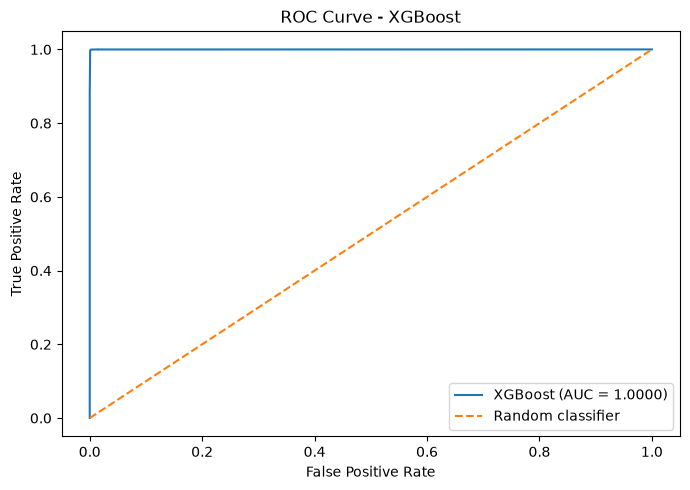

Average Precision: 0.999755


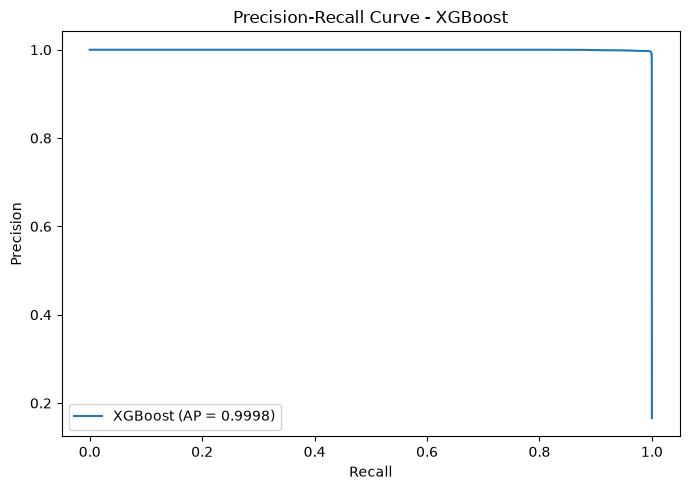

In [132]:

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Probability that each test flow is an attack
y_score_xgb = best_model_group.predict_proba(X_test_group)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test_group, y_score_xgb
)
roc_auc = auc(fpr, tpr)

print("ROC-AUC:", round(roc_auc, 6))

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.tight_layout()
plt.show()

# Precision-Recall curve
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_test_group, y_score_xgb)
)

avg_precision = average_precision_score(
    y_test_group, y_score_xgb
)

print("Average Precision:", round(avg_precision, 6))

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values,
    precision_values,
    label=f"XGBoost (AP = {avg_precision:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGBoost")
plt.legend()
plt.tight_layout()
plt.show()

Top 20 important features:


,Feature,Importance
0,Bwd Packet Length Std,0.287827
1,Average Packet Size,0.237869
2,Bwd Header Length,0.158703
3,Idle Mean,0.060171
4,Flow Bytes/s,0.056404
5,Max Packet Length,0.050914
6,Fwd Packet Length Std,0.013147
7,Destination Port,0.009202
8,Total Length of Bwd Packets,0.009169
9,Bwd IAT Mean,0.008359


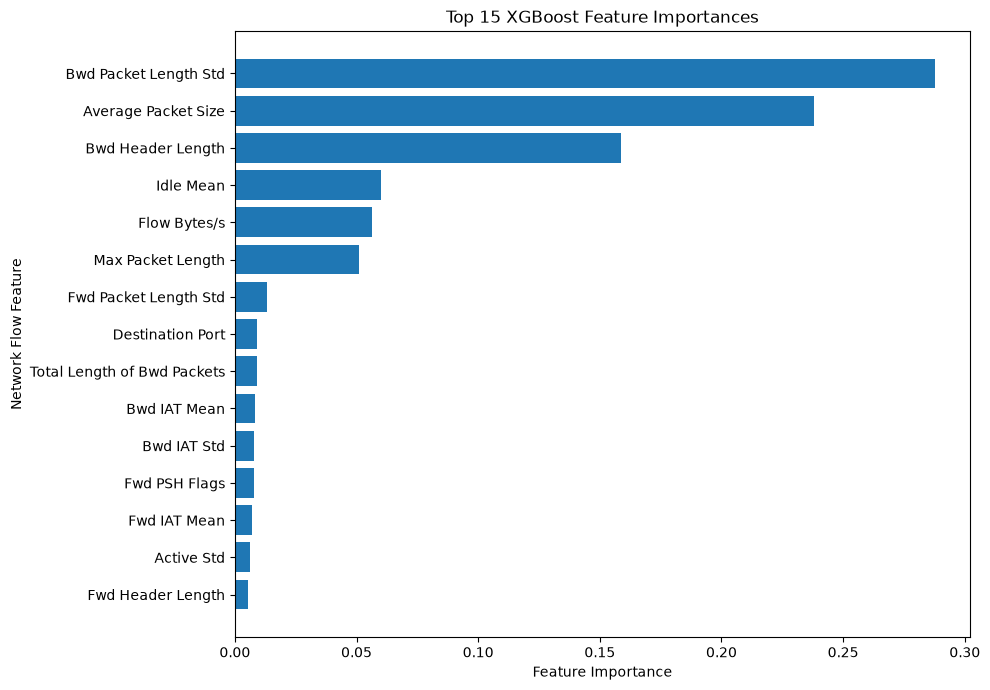

In [135]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as show_table

# Extract feature importance from the trained XGBoost model
feature_importance = pd.DataFrame({
    "Feature": X_train_group.columns,
    "Importance": best_model_group.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 important features:")
show_table(feature_importance.head(20))

# Plot the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Network Flow Feature")
plt.title("Top 15 XGBoost Feature Importances")
plt.tight_layout()
plt.show()

In [136]:
%pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ------------- -------------------------- 262.1/755.4 kB ? eta -:--:--
   --------------------------- ------------ 524.3/755.4 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 755.4/755.4 kB 1.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Network-Intrusion-Detection\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP calculation completed.
Sample shape: (1000, 78)


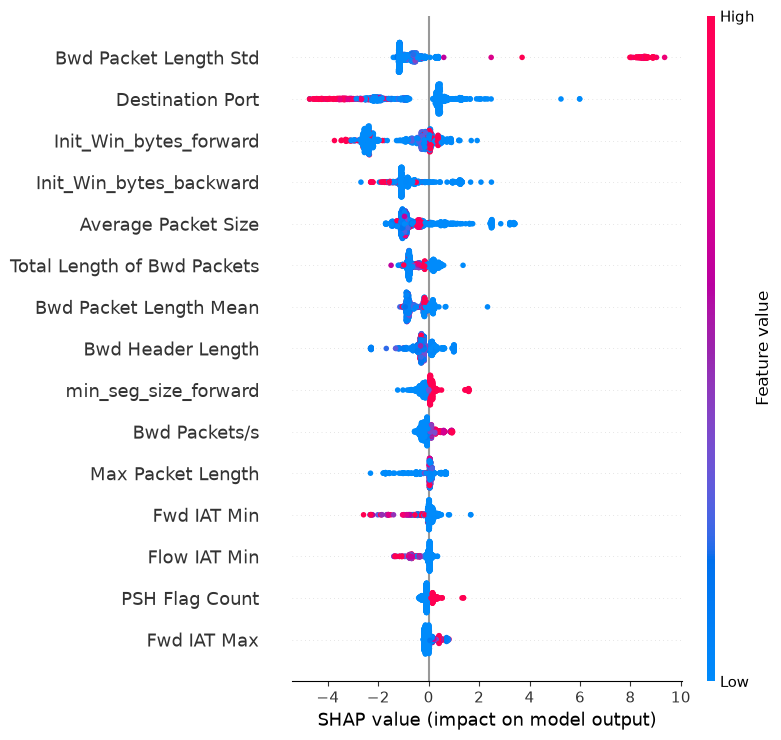

In [137]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# Sample test records for explanation
X_shap = X_test_group.sample(
    n=1000,
    random_state=42
)

# Explain the trained XGBoost model
explainer = shap.TreeExplainer(best_model_group)
shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed.")
print("Sample shape:", X_shap.shape)

# Global explanation: which features influence predictions most?
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15,
    show=True
)

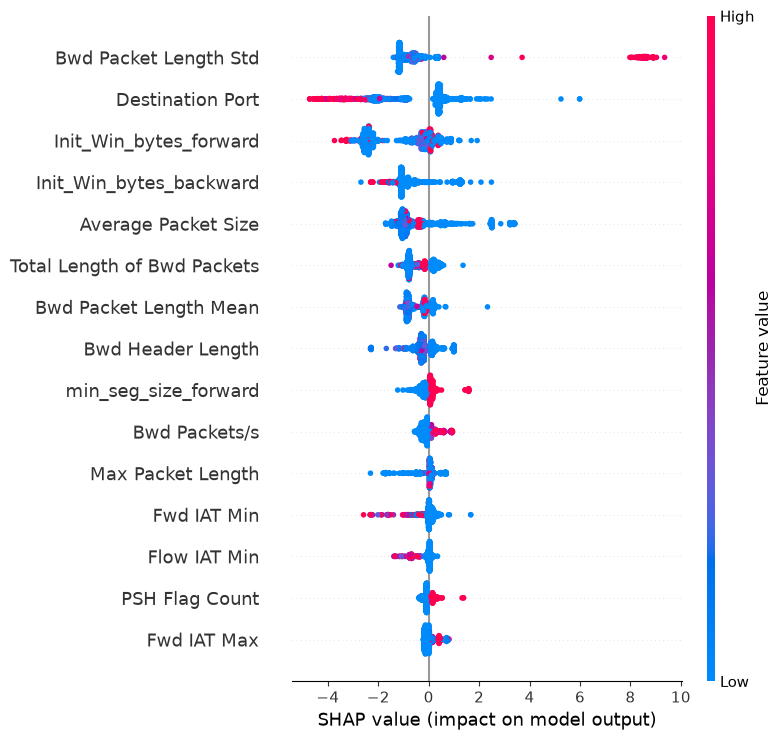

In [138]:
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15,
    show=True
)

In [139]:
import numpy as np
import pandas as pd

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print(shap_importance.head(15).to_string(index=False))

                    Feature  Mean_Absolute_SHAP
      Bwd Packet Length Std            1.481543
           Destination Port            1.354761
     Init_Win_bytes_forward            1.210328
    Init_Win_bytes_backward            0.992980
        Average Packet Size            0.960338
Total Length of Bwd Packets            0.500809
     Bwd Packet Length Mean            0.494037
          Bwd Header Length            0.352451
       min_seg_size_forward            0.208158
              Bwd Packets/s            0.204256
          Max Packet Length            0.194622
                Fwd IAT Min            0.174357
               Flow IAT Min            0.149613
             PSH Flag Count            0.149029
                Fwd IAT Max            0.135060


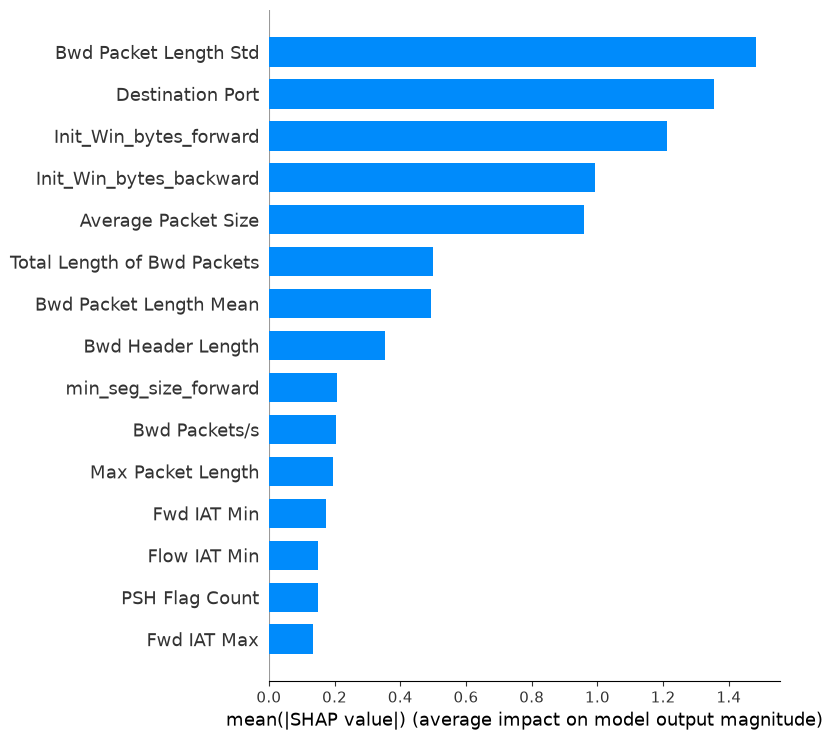

In [140]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=15,
    show=True
)

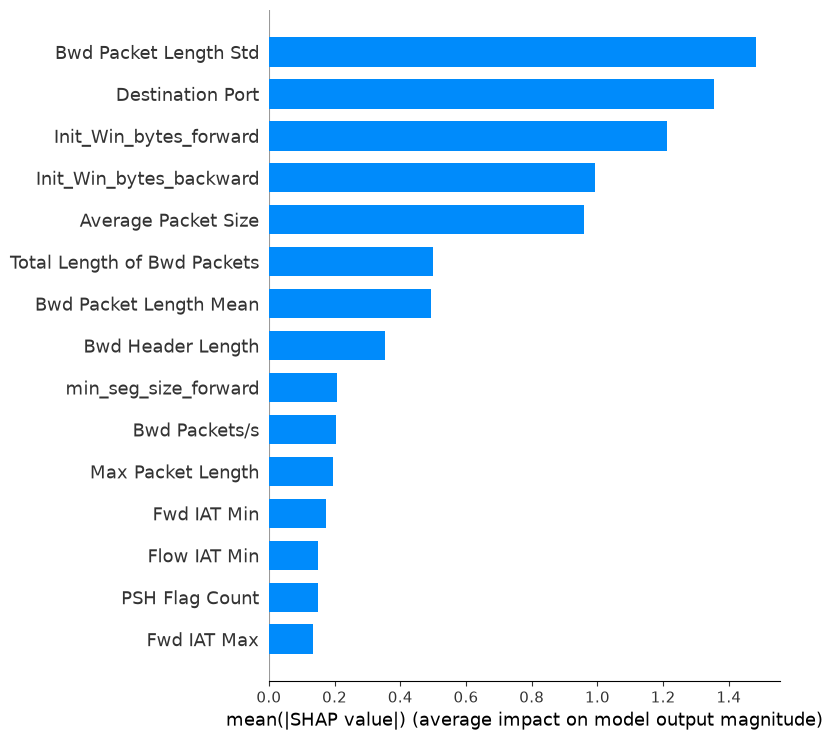

SHAP plot saved successfully!
Current working directory: c:\Network-Intrusion-Detection\notebooks
Save location: c:\Network-Intrusion-Detection\reports\shap_feature_importance.png


In [142]:
import os
import matplotlib.pyplot as plt
import shap

# Create the reports folder if it does not exist
os.makedirs("../reports", exist_ok=True)

# Generate the SHAP feature importance bar plot
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=15,
    show=False
)

# Save the plot
plt.savefig(
    "../reports/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP plot saved successfully!")
print("Current working directory:", os.getcwd())
print("Save location:", os.path.abspath("../reports/shap_feature_importance.png"))

In [143]:
# Combine the training and testing data for checking
all_features = pd.concat(
    [X_train_group, X_test_group],
    axis=0
)

all_labels = pd.concat(
    [y_train_group, y_test_group],
    axis=0
)

# Identify duplicate feature rows
feature_hashes = pd.util.hash_pandas_object(
    all_features,
    index=False
)

check_df = pd.DataFrame({
    "hash": feature_hashes.to_numpy(),
    "label": all_labels.to_numpy()
})

# Count distinct labels for each feature hash
label_counts = check_df.groupby("hash")["label"].nunique()

conflicting_hashes = label_counts[label_counts > 1]

print("Number of feature groups with conflicting labels:",
      len(conflicting_hashes))

Number of feature groups with conflicting labels: 697


In [144]:

# Count rows belonging to conflicting feature groups
conflicting_rows = check_df[
    check_df["hash"].isin(conflicting_hashes.index)
]

print("Conflicting feature groups:", len(conflicting_hashes))
print("Rows belonging to conflicting groups:", len(conflicting_rows))
print("\nBinary label counts among conflicting rows:")
print(conflicting_rows["label"].value_counts())

print("\nLabels per conflicting feature group:")
print(label_counts[label_counts > 1].value_counts().sort_index())

Conflicting feature groups: 697
Rows belonging to conflicting groups: 1412

Binary label counts among conflicting rows:
label
0    715
1    697
Name: count, dtype: int64

Labels per conflicting feature group:
label
2    697
Name: count, dtype: int64


In [145]:

# Use the original cleaned dataframe, df
# feature_cols should contain the same 78 feature columns
df_check = df[feature_cols].copy()

# Create a hash for each feature row
df_check["feature_hash"] = pd.util.hash_pandas_object(
    df[feature_cols],
    index=False
).to_numpy()

# Attach the original labels
df_check["original_label"] = (
    df["Label"].astype(str).str.strip().to_numpy()
)

# Select groups containing more than one original label
original_label_counts = (
    df_check.groupby("feature_hash")["original_label"].nunique()
)

original_conflicting_hashes = original_label_counts[
    original_label_counts > 1
].index

original_conflicts = df_check[
    df_check["feature_hash"].isin(original_conflicting_hashes)
]

print("Groups with multiple original labels:",
      len(original_conflicting_hashes))

print("\nOriginal label combinations:")
label_combinations = (
    original_conflicts.groupby("feature_hash")["original_label"]
    .agg(lambda labels: " | ".join(sorted(set(labels))))
    .value_counts()
)

print(label_combinations.to_string())

Groups with multiple original labels: 697

Original label combinations:
original_label
BENIGN | PortScan         564
BENIGN | DoS Hulk         129
BENIGN | DDoS               3
BENIGN | DoS slowloris      1


In [146]:

# Count rows by original label in the conflicting groups
print("Rows by original label in conflicting groups:")
print(
    original_conflicts["original_label"]
    .value_counts()
    .to_string()
)

# Compare with the complete dataset
print("\nPercentage of the complete dataset involved:")
print(
    round(
        len(original_conflicts) / len(df) * 100,
        5
    ),
    "%"
)

Rows by original label in conflicting groups:
original_label
BENIGN           715
PortScan         564
DoS Hulk         129
DDoS               3
DoS slowloris      1

Percentage of the complete dataset involved:
0.05489 %


In [147]:

# Identify feature hashes belonging to conflicting groups
conflict_hash_set = set(original_conflicting_hashes)

# Hash rows in the group-aware test set
test_feature_hashes = pd.util.hash_pandas_object(
    X_test_group,
    index=False
)

# Mark test rows whose feature hashes are in the conflicting groups
test_conflict_mask = test_feature_hashes.isin(
    conflict_hash_set
)

print("Test-set rows:", len(X_test_group))
print("Rows in conflicting groups:", test_conflict_mask.sum())
print("Rows remaining after exclusion:",
      (~test_conflict_mask).sum())

Test-set rows: 514705
Rows in conflicting groups: 305
Rows remaining after exclusion: 514400


In [148]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Keep only test rows outside conflicting feature groups
X_test_clean = X_test_group.loc[~test_conflict_mask]
y_test_clean = y_test_group.loc[~test_conflict_mask]

# Predict using the existing trained model
y_pred_clean = best_model_group.predict(X_test_clean)

# Calculate metrics
print("Sensitivity Analysis: Excluding Conflicting Groups")
print("-" * 55)
print("Test rows retained:", len(X_test_clean))
print("Accuracy :", round(accuracy_score(y_test_clean, y_pred_clean), 6))
print("Precision:", round(precision_score(y_test_clean, y_pred_clean, zero_division=0), 6))
print("Recall   :", round(recall_score(y_test_clean, y_pred_clean, zero_division=0), 6))
print("F1-score :", round(f1_score(y_test_clean, y_pred_clean, zero_division=0), 6))

print("\nClassification Report:")
print(classification_report(
    y_test_clean,
    y_pred_clean,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

Sensitivity Analysis: Excluding Conflicting Groups
-------------------------------------------------------
Test rows retained: 514400
Accuracy : 0.99923
Precision: 0.997982
Recall   : 0.997374
F1-score : 0.997678

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    429097
      ATTACK       1.00      1.00      1.00     85303

    accuracy                           1.00    514400
   macro avg       1.00      1.00      1.00    514400
weighted avg       1.00      1.00      1.00    514400



In [149]:

# Recover original labels for the group-aware test indices
y_test_original_labels = (
    df.loc[X_test_group.index, "Label"]
    .astype(str)
    .str.strip()
)

# Use predictions already generated for the original test set
y_pred_original = best_model_group.predict(X_test_group)

# Build a category-level evaluation table
category_results = []

for attack_name in sorted(y_test_original_labels.unique()):
    mask = y_test_original_labels == attack_name

    actual_binary = y_test_group.loc[mask]
    predicted_binary = pd.Series(
        y_pred_original,
        index=X_test_group.index
    ).loc[mask]

    category_results.append({
        "Original_Category": attack_name,
        "Test_Rows": int(mask.sum()),
        "Correct_Binary_Predictions": int(
            (actual_binary.to_numpy() ==
             predicted_binary.to_numpy()).sum()
        ),
        "Accuracy": round(
            accuracy_score(actual_binary, predicted_binary), 6
        )
    })

category_results_df = pd.DataFrame(category_results)

print(
    category_results_df.sort_values("Accuracy").to_string(index=False)
)

         Original_Category  Test_Rows  Correct_Binary_Predictions  Accuracy
              Infiltration          6                           0  0.000000
                Heartbleed          1                           0  0.000000
Web Attack � Sql Injection          4                           1  0.250000
                       Bot        421                         285  0.676960
          Web Attack � XSS        135                         130  0.962963
  Web Attack � Brute Force        304                         295  0.970395
          DoS Slowhttptest       1023                        1012  0.989247
               SSH-Patator        586                         581  0.991468
             DoS GoldenEye       2070                        2066  0.998068
             DoS slowloris       1109                        1107  0.998197
                      DDoS      25729                       25700  0.998873
               FTP-Patator       1188                        1187  0.999158
            

In [150]:

# Align predictions and attack probabilities with test-set indices
predictions = pd.Series(
    y_pred_original,
    index=X_test_group.index
)

attack_probabilities = pd.Series(
    best_model_group.predict_proba(X_test_group)[:, 1],
    index=X_test_group.index
)

# Identify Bot traffic in the test set
bot_mask = y_test_original_labels.eq("Bot")

# Bot rows incorrectly predicted as BENIGN
bot_false_negatives = bot_mask & predictions.eq(0)

print("Total Bot test rows:", int(bot_mask.sum()))
print("Bot rows correctly detected:",
      int((bot_mask & predictions.eq(1)).sum()))
print("Bot rows missed:",
      int(bot_false_negatives.sum()))

print("\nAttack probability for missed Bot rows:")
print(
    attack_probabilities[bot_false_negatives]
    .describe()
)

print("\nFive missed Bot rows with the lowest attack probability:")
bot_missed_sample = X_test_group.loc[bot_false_negatives].copy()
bot_missed_sample["Attack_Probability"] = (
    attack_probabilities[bot_false_negatives]
)
print(
    bot_missed_sample
    .sort_values("Attack_Probability")
    .head(5)
    .to_string()
)

Total Bot test rows: 421
Bot rows correctly detected: 285
Bot rows missed: 136

Attack probability for missed Bot rows:
count    136.000000
mean       0.328898
std        0.125109
min        0.000220
25%        0.336608
50%        0.364264
75%        0.396988
max        0.462383
dtype: float64

Five missed Bot rows with the lowest attack probability:
        Destination Port  Flow Duration  Total Fwd Packets  Total Backward Packets  Total Length of Fwd Packets  Total Length of Bwd Packets  Fwd Packet Length Max  Fwd Packet Length Min  Fwd Packet Length Mean  Fwd Packet Length Std  Bwd Packet Length Max  Bwd Packet Length Min  Bwd Packet Length Mean  Bwd Packet Length Std  Flow Bytes/s  Flow Packets/s  Flow IAT Mean  Flow IAT Std  Flow IAT Max  Flow IAT Min  Fwd IAT Total  Fwd IAT Mean  Fwd IAT Std  Fwd IAT Max  Fwd IAT Min  Bwd IAT Total  Bwd IAT Mean  Bwd IAT Std  Bwd IAT Max  Bwd IAT Min  Fwd PSH Flags  Bwd PSH Flags  Fwd URG Flags  Bwd URG Flags  Fwd Header Length  Bwd Header Length

In [151]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Probabilities for the complete group-aware test set
y_prob = best_model_group.predict_proba(X_test_group)[:, 1]

threshold_results = []

for threshold in [0.50, 0.40, 0.30, 0.20]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    # Overall binary classification performance
    overall_precision = precision_score(
        y_test_group, y_pred_threshold, zero_division=0
    )
    overall_recall = recall_score(
        y_test_group, y_pred_threshold, zero_division=0
    )
    overall_f1 = f1_score(
        y_test_group, y_pred_threshold, zero_division=0
    )

    # Bot detection rate at this threshold
    bot_actual = y_test_original_labels.eq("Bot").to_numpy()
    bot_detected = (y_pred_threshold == 1) & bot_actual

    threshold_results.append({
        "Threshold": threshold,
        "Overall_Precision": round(overall_precision, 6),
        "Overall_Recall": round(overall_recall, 6),
        "Overall_F1": round(overall_f1, 6),
        "Bot_Detected": int(bot_detected.sum()),
        "Bot_Total": int(bot_actual.sum()),
        "Bot_Recall": round(
            bot_detected.sum() / bot_actual.sum(), 6
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)
print(threshold_results_df.to_string(index=False))

 Threshold  Overall_Precision  Overall_Recall  Overall_F1  Bot_Detected  Bot_Total  Bot_Recall
       0.5           0.996201        0.997367    0.996784           285        421    0.676960
       0.4           0.995842        0.997660    0.996750           295        421    0.700713
       0.3           0.993334        0.999146    0.996231           402        421    0.954869
       0.2           0.991075        0.999333    0.995187           402        421    0.954869


In [152]:

from sklearn.metrics import confusion_matrix

for threshold in [0.50, 0.30]:
    predictions_at_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_group,
        predictions_at_threshold,
        labels=[0, 1]
    ).ravel()

    print(f"\nThreshold: {threshold:.2f}")
    print("True negatives :", tn)
    print("False positives:", fp)
    print("False negatives:", fn)
    print("True positives :", tp)


Threshold: 0.50
True negatives : 428926
False positives: 325
False negatives: 225
True positives : 85229

Threshold: 0.30
True negatives : 428678
False positives: 573
False negatives: 73
True positives : 85381


In [153]:

import pandas as pd

threshold_comparison = pd.DataFrame([
    {
        "Threshold": 0.50,
        "True_Negatives": 428926,
        "False_Positives": 325,
        "False_Negatives": 225,
        "True_Positives": 85229
    },
    {
        "Threshold": 0.30,
        "True_Negatives": 428678,
        "False_Positives": 573,
        "False_Negatives": 73,
        "True_Positives": 85381
    }
])

import os
os.makedirs("../reports", exist_ok=True)

threshold_comparison.to_csv(
    "../reports/threshold_comparison.csv",
    index=False
)

print("Threshold comparison saved successfully.")
print(threshold_comparison.to_string(index=False))

Threshold comparison saved successfully.
 Threshold  True_Negatives  False_Positives  False_Negatives  True_Positives
       0.5          428926              325              225           85229
       0.3          428678              573               73           85381


In [154]:

import os

os.makedirs("../reports", exist_ok=True)

# Save the existing model comparison results
results_group_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")
print(results_group_df.to_string(index=False))

Model comparison saved successfully.
              Model  Accuracy  Precision   Recall  F1-score
            XGBoost  0.998931   0.996201 0.997367  0.996784
      Random Forest  0.998762   0.996325 0.996220  0.996273
      Decision Tree  0.998624   0.995857 0.995857  0.995857
Logistic Regression  0.956797   0.877176 0.860229  0.868620


In [155]:

import os
import pandas as pd

os.makedirs("../reports", exist_ok=True)

summary = pd.DataFrame([
    {
        "Experiment": "XGBoost - group-aware test split",
        "Metric": "Accuracy",
        "Value": 0.998931,
        "Notes": "Threshold 0.50"
    },
    {
        "Experiment": "XGBoost - group-aware test split",
        "Metric": "Precision",
        "Value": 0.996201,
        "Notes": "Threshold 0.50"
    },
    {
        "Experiment": "XGBoost - group-aware test split",
        "Metric": "Recall",
        "Value": 0.997367,
        "Notes": "Threshold 0.50"
    },
    {
        "Experiment": "XGBoost - group-aware test split",
        "Metric": "F1-score",
        "Value": 0.996784,
        "Notes": "Threshold 0.50"
    },
    {
        "Experiment": "XGBoost - group-aware test split",
        "Metric": "ROC-AUC",
        "Value": 0.999952,
        "Notes": "Computed using predicted probabilities"
    },
    {
        "Experiment": "XGBoost - group-aware test split",
        "Metric": "Average Precision",
        "Value": 0.999755,
        "Notes": "Precision-recall evaluation"
    },
    {
        "Experiment": "Label-conflict investigation",
        "Metric": "Conflicting feature groups",
        "Value": 697,
        "Notes": "Original labels include BENIGN and attack categories"
    },
    {
        "Experiment": "Bot category evaluation",
        "Metric": "Bot recall",
        "Value": 0.676960,
        "Notes": "At threshold 0.50; 285 of 421 detected"
    }
])

summary.to_csv("../reports/experiment_summary.csv", index=False)

print("Experiment summary saved successfully.")
print(summary.to_string(index=False))

Experiment summary saved successfully.
                      Experiment                     Metric      Value                                                Notes
XGBoost - group-aware test split                   Accuracy   0.998931                                       Threshold 0.50
XGBoost - group-aware test split                  Precision   0.996201                                       Threshold 0.50
XGBoost - group-aware test split                     Recall   0.997367                                       Threshold 0.50
XGBoost - group-aware test split                   F1-score   0.996784                                       Threshold 0.50
XGBoost - group-aware test split                    ROC-AUC   0.999952               Computed using predicted probabilities
XGBoost - group-aware test split          Average Precision   0.999755                          Precision-recall evaluation
    Label-conflict investigation Conflicting feature groups 697.000000 Original labels includ

In [156]:

import pandas as pd

# Create a combined table of train and test features
train_check = X_train_group.copy()
train_check["target"] = y_train_group.to_numpy()
train_check["split"] = "train"

test_check = X_test_group.copy()
test_check["target"] = y_test_group.to_numpy()
test_check["split"] = "test"

combined_check = pd.concat(
    [train_check, test_check],
    axis=0
)

# Count exact feature combinations appearing in both splits
train_hashes = pd.util.hash_pandas_object(
    X_train_group, index=False
)
test_hashes = pd.util.hash_pandas_object(
    X_test_group, index=False
)

train_hash_set = set(train_hashes)
test_hash_set = set(test_hashes)

overlap_count = len(train_hash_set.intersection(test_hash_set))

print("Unique train feature hashes:", len(train_hash_set))
print("Unique test feature hashes:", len(test_hash_set))
print("Feature hashes appearing in both splits:", overlap_count)

# Check whether matching feature rows have conflicting binary labels
train_label_lookup = pd.DataFrame({
    "hash": train_hashes.to_numpy(),
    "target": y_train_group.to_numpy()
})

test_label_lookup = pd.DataFrame({
    "hash": test_hashes.to_numpy(),
    "target": y_test_group.to_numpy()
})

train_label_lookup = train_label_lookup.drop_duplicates()

matching_rows = test_label_lookup.merge(
    train_label_lookup,
    on="hash",
    suffixes=("_test", "_train")
)

conflicts = matching_rows[
    matching_rows["target_test"] != matching_rows["target_train"]
]

print("Matching rows with conflicting binary labels:",
      len(conflicts))

Unique train feature hashes: 2016080
Unique test feature hashes: 504021
Feature hashes appearing in both splits: 0
Matching rows with conflicting binary labels: 0


In [157]:

# Count repeated feature combinations within each split

train_hashes = pd.util.hash_pandas_object(
    X_train_group, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test_group, index=False
)

print("TRAINING SET")
print("Total rows:", len(X_train_group))
print("Unique feature combinations:", train_hashes.nunique())
print("Repeated rows:",
      len(X_train_group) - train_hashes.nunique())

print("\nTEST SET")
print("Total rows:", len(X_test_group))
print("Unique feature combinations:", test_hashes.nunique())
print("Repeated rows:",
      len(X_test_group) - test_hashes.nunique())

TRAINING SET
Total rows: 2057935
Unique feature combinations: 2016080
Repeated rows: 41855

TEST SET
Total rows: 514705
Unique feature combinations: 504021
Repeated rows: 10684


In [2]:

def check_duplicate_labels(X, y, split_name):
    data = X.copy()
    data["_target"] = y.to_numpy()

    # Number of distinct labels for each feature combination
    label_counts = data.groupby(
        list(X.columns),
        dropna=False
    )["_target"].nunique()

    conflicting_groups = label_counts[label_counts > 1]

    print(f"\n{split_name}")
    print("Total feature groups:", len(label_counts))
    print("Groups with conflicting binary labels:",
          len(conflicting_groups))

    return conflicting_groups


train_conflicts = check_duplicate_labels(
    X_train_group, y_train_group, "TRAINING SET"
)

test_conflicts = check_duplicate_labels(
    X_test_group, y_test_group, "TEST SET"
)

NameError: name 'X_train_group' is not defined

In [ ]:

def summarize_conflicting_rows(X, y, split_name):
    data = X.copy()
    data["_target"] = y.to_numpy()

    grouped = data.groupby(
        list(X.columns),
        dropna=False
    )["_target"]

    # Identify feature combinations containing both binary labels
    conflicting_groups = grouped.nunique()
    conflicting_groups = conflicting_groups[
        conflicting_groups > 1
    ]

    # Count every row belonging to those feature combinations
    group_sizes = grouped.size()

    conflicting_rows = group_sizes.loc[
        conflicting_groups.index
    ].sum()

    print(f"\n{split_name}")
    print("Conflicting feature groups:",
          len(conflicting_groups))
    print("Rows belonging to those groups:",
          int(conflicting_rows))
    print("Percentage of split:",
          round(100 * conflicting_rows / len(X), 5), "%")


summarize_conflicting_rows(
    X_train_group, y_train_group, "TRAINING SET"
)

summarize_conflicting_rows(
    X_test_group, y_test_group, "TEST SET"
)

NameError: name 'X_train_group' is not defined

In [13]:

import os

project_root = os.path.abspath("..")

model_extensions = (".pkl", ".joblib", ".ubj", ".model")

model_files = []

for root, dirs, files in os.walk(project_root):
    # Exclude unrelated and large folders
    dirs[:] = [
        d for d in dirs
        if d not in {
            "venv", ".git", "Qt", "__pycache__",
            "node_modules"
        }
    ]

    for file in files:
        if file.lower().endswith(model_extensions):
            model_files.append(os.path.join(root, file))

print("Potential ML model files found:", len(model_files))

for path in model_files:
    print(path)

if not model_files:
    print("\nNo saved ML model files found in the searched folders.")

Potential ML model files found: 0

No saved ML model files found in the searched folders.
